# 4. Vectors

*Physical Modeling in MATLAB* by Allen B. Downey. Run each code cell in order with Shift+Enter; you can change the code and run it again.

In the previous chapter we used a loop to compute the elements of a sequence, but we were only able to store the last element. In this chapter, we’ll use a vector to store all of the elements. We’ll also learn how to select elements from a vector, and how to perform vector arithmetic and common vector operations like reduce and apply.

## Creating Vectors

A *vector* in MATLAB is a sequence of numbers. There are several ways to create vectors; one of the most common is to put a sequence of numbers in square brackets:

In [ ]:
[1 2 3]

Another way to create a vector is the colon operator, which we have already used to create a range of values in a `for` loop.

In [ ]:
1:3

In general, anything you can do with a number, you can also do with a vector. For example, you can assign a vector value to a variable:

In [ ]:
X = [1 2 3]

Note that variables that contain vectors are often capital letters. That’s just a convention; MATLAB doesn’t require it, but it’s a useful way to remember which variables are vectors.

## Vector Arithmetic

As with numbers, you can do arithmetic with vectors. If you add a number to a vector, MATLAB increments each element of the vector:

In [ ]:
Y = X + 5

The result is a new vector; the original value of `X` has not changed.

If you add two vectors, MATLAB adds the corresponding elements of each vector and creates a new vector that contains the sums:

In [ ]:
Z = X + Y

But adding vectors only works if the operands are the same size. Otherwise you get an error:

```
W = [1 2]
X + W
```

In MATLAB, the error message is:

```
Matrix dimensions must agree.
```

In Octave, it is:

```
error: operator +: nonconformant arguments (op1 is 1x3, op2 is 1x2)
```

This error message might be confusing, because we think of `X` and `W` as vectors, not matrices. But in MATLAB, a vector is a kind of matrix. We’ll come back to matrices later, but in the meantime, you might see the term in error messages and documentation.

If you divide two vectors, you might be surprised by the result:

In [ ]:
X / Y

MATLAB is performing an operation called right division, which is not what we expected. To divide the elements of `X` by the elements of `Y`, you have to use `./`, which is element-wise division:

In [ ]:
X ./ Y

Multiplication has the same problem. If you use `*`, MATLAB does matrix multiplication. With these two vectors, matrix multiplication is not defined, so you get an error:

```
X * Y
```

In MATLAB, the error message is:

```
Error using  *
Incorrect dimensions for matrix multiplication.
Check that the number of columns in the first matrix
matches the number of rows in the second matrix.
To perform element-wise multiplication, use '.*'.
```

In Octave, it is:

```
error: operator *: nonconformant arguments (op1 is 1x3, op2 is 1x3)
```

In this case, the error message is pretty helpful. As it suggests, you can use `.*` to perform element-wise multiplication:

In [ ]:
X .* Y

As an exercise, see what happens if you use the exponentiation operator (`^`) with a vector.

## Selecting Elements

You can select an element from a vector with parentheses:

In [ ]:
Y = [6 7 8 9]
Y(1)
Y(4)

This means that the first element of `Y` is `6` and the fourth element is `9`. The number in parentheses is called the *index* because it indicates which element of the vector you want.

The index can be a variable name or a mathematical expression:

In [ ]:
i = 1;
Y(i)
Y(i+1)

We can use a loop to display the elements of `Y`:

In [ ]:
for i=1:4
     Y(i)
end

Each time through the loop we use a different value of `i` as an index into `Y`.

In the previous example we had to know the number of elements in `Y`. We can make it more general by using the `length` function, which returns the number of elements in a vector:

In [ ]:
for i=1:length(Y)
     Y(i)
end

This version works for a vector of any length.

## Indexing Errors

An index can be any kind of expression, but the value of the expression has to be a positive integer, and it has to be less than or equal to the length of the vector. If it’s zero or negative, you’ll get an error:

```
Y(0)
```

In MATLAB, the error message is:

```
Array indices must be positive integers or logical values.
```

In Octave, it is:

```
error: Y(0): subscripts must be either integers 1 to (2^63)-1 or logicals
```

If it’s not an integer, you get an error:

```
Y(1.5)
```

In MATLAB, the error message is:

```
Array indices must be positive integers or logical values.
```

In Octave, it is:

```
error: Y(1.5): subscripts must be either integers 1 to (2^63)-1 or logicals
```

If the index is too big, you also get an error:

```
Y(5)
```

In MATLAB, the error message is:

```
Index exceeds the number of array elements (4).
```

In Octave, it is:

```
error: Y(5): out of bound 4 (dimensions are 1x4)
```

The error messages use the word *array* rather than *matrix*, but they mean the same thing, at least for now.

## Vectors and Sequences

Vectors and sequences go together nicely. For example, another way to evaluate the Fibonacci sequence from Chapter 2 is to store successive values in a vector. Remember that the definition of the Fibonacci sequence is $F_1 = 1$, $F_2 = 1$, and $F_{i} = F_{i-1} + F_{i-2}$ for $i > 2$.

Listing 4.1 shows how we can compute the elements of this sequence and store them in a vector, using a capital letter for the vector `F` and lower-case letters for the integers `i` and `n`.

*Listing 4.1: Calculating the Fibonacci sequence using a vector*

In [ ]:
n = 10      % the number of elements (Figure 4.1 shows the first 10)
F(1) = 1
F(2) = 1
for i=3:n
    F(i) = F(i-1) + F(i-2)
end

If you had any trouble with Exercise 3.6, you have to appreciate the simplicity of this script. The MATLAB syntax is similar to the math notation, which makes it easier to check for correctness.

If you only want the $n$th Fibonacci number, storing the whole sequence wastes some space. But if wasting space makes your code easier to write and debug, that’s probably okay.

## Plotting Vectors

If you call `plot` with a vector as an argument, MATLAB plots the indices on the x-axis and the elements on the y-axis. To plot the Fibonacci numbers we computed in Listing 4.1, we’d use

In [ ]:
plot(F)

Figure 4.1 shows the result.

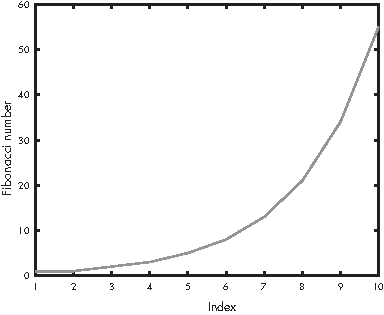

*Figure 4.1: The first 10 elements of the Fibonacci sequence*

This way of looking at a vector is often useful for debugging, especially if it is big enough that displaying the elements on the screen is unwieldy.

## Common Vector Operations

We’ve covered some of the basic features of vectors. Let’s now look at some common patterns we use to work with data stored in vectors.

### Reduce

We frequently use loops to run through the elements of a vector and add them up, multiply them together, compute the sum of their squares, and so on. This kind of operation is called *reduce*, because it reduces a vector with multiple elements down to a single number.

For example, the loop in Listing 4.2 adds up the elements of a vector named `X` (which we assume has been defined).

*Listing 4.2: Reducing a vector to a single scalar value (the sum)*

In [ ]:
total = 0
for i=1:length(X)
    total = total + X(i)
end
ans = total

The use of `total` as an accumulator is similar to what we saw in Chapter 3. Again, we use the `length` function to find the upper bound of the range, so this loop will work regardless of the length of `X`. Each time through the loop, we add in the `i`th element of `X`, so at the end of the loop `total` contains the sum of the elements.

MATLAB provides functions that perform some reduce operations. For example, the `sum` function computes the sum of the elements in a vector, and `prod` computes the product.

### Apply

Another common use of a loop is to run through the elements of a vector, perform some operation on the elements, and create a new vector with the results. This operation is called *apply*, because you apply the operation to each element in the vector.

For example, the loop in Listing 4.3 creates a vector `Y` that contains the squares of the elements of `X` (assuming, again, that `X` is already defined).

*Listing 4.3: Making a new vector Y by squaring the elements in X*

In [ ]:
clear Y     % Y is still [6 7 8 9] from above; without this, the result would end with the 9
for i=1:length(X)
    Y(i) = X(i)^2
end

Many apply operations can be done with element-wise operators. The following statement is more concise than the loop in Listing 4.3.

In [ ]:
Y = X .^ 2

It also runs faster!

## Chapter Review

In this chapter, we used a vector to store the elements of a sequence. We learned how to select elements from a vector and perform vector arithmetic. We performed reduce and apply operations using `for` loops, MATLAB functions, and element-wise operations.

Here are some terms from this chapter you might want to remember.

A *vector* is a sequence of values, which is a kind of *matrix*, also called an *array* in some MATLAB documentation.

An *index* is an integer value used to indicate one of the elements in a vector or matrix (also called a *subscript* in some MATLAB documentation).

An operation is *element-wise* if it acts on the individual elements of a vector or matrix (unlike some linear algebra operations).

You can *apply* an operation to all elements of a vector, and you can *reduce* a vector to a single value, for example by computing the sum of the elements.

In the next chapter, we’ll meet the most important idea in computer programming: functions!

## Exercises

Before you go on, you might want to work on the following exercises.

**Exercise 4.1.** Write a loop that computes the first $n$ elements of the geometric sequence $A_{i+1} = A_i/2$ with $A_1 = 1$. Notice that math notation puts $A_{i+1}$ on the left side of the equality. When you translate to MATLAB, you might want to rewrite it with $A_{i}$ on the left side.

**Exercise 4.2.** Write an expression that computes the square root of the sum of the squares of the elements of a vector, without using a loop.

**Exercise 4.3.** The ratio of consecutive Fibonacci numbers, $F_{n+1}/F_{n}$, converges to a constant value as $n$ increases. Write a script that computes a vector with the first $n$ elements of a Fibonacci sequence (assuming that the variable `n` is defined) and then computes a new vector that contains the ratios of consecutive Fibonacci numbers. Plot this vector to see if it seems to converge. What value does it converge on?

**Exercise 4.4.** The following set of equations is based on a famous example of a chaotic system, the Lorenz attractor (see <https://greenteapress.com/matlab/lorenz>):

$$\begin{aligned}
x_{i+1} &= x_i + \sigma \left( y_i - x_i \right) dt  \\
y_{i+1} &= y_i + \left[ x_i (r - z_i) - y_i \right] dt   \\
z_{i+1} &= z_i + \left( x_i y_i - b z_i \right) dt
\end{aligned}$$

1.  Write a script that computes the first 10 elements of the sequences $X$, $Y$, and $Z$ and stores them in vectors named **`X`**, **`Y`**, and **`Z`**.

    Use the initial values $X_1 = 1$, $Y_1 = 2$, and $Z_1 = 3$ with the values $\sigma = 10$, $b = 8/3$, $r = 28$, and $dt = 0.01$.

2.  Read the documentation for `plot3` and `comet3`, and plot the results in three dimensions.

3.  Once the code is working, use semicolons to suppress the output and then run the program with sequence lengths of 100, 1,000, and 10,000.

4.  Run the program again with different starting conditions. What effect does it have on the result?

5.  Run the program with different values for $\sigma$, $b$, and $r$, and see if you can get a sense of how each variable affects the system.

**Exercise 4.5.** The logistic map (see <https://greenteapress.com/matlab/logistic>) is described by the following equation:

$$X_{i+1} = r X_i (1-X_i)$$ where $X_i$ is a number between 0 and 1, and $r$ is a positive number.

1.  Write a script named *logmap.m* that computes the first 50 elements of $X$ with `r` = 3.9 and `X1` = 0.5, where `r` is the parameter of the logistic map and `X1` is the initial value.

2.  Plot the results for a range of values of $r$ from 2.4 to 4.0. How does the behavior of the system change as you vary $r$?

In [ ]:
% Exercise 4.1: your solution here


In [ ]:
% Exercise 4.2: your solution here


In [ ]:
% Solution

% Plot the ratios of successive elements of a Fibonacci sequence
% Precondition: `n` is a positive integer.

F(1) = 1
F(2) = 1
for i=3:n
    F(i) = F(i-1) + F(i-2)
end

for i=1:n-1
    D(i) = F(i+1) / F(i)
end

plot(D)

In [ ]:
% Solution

clear all
X(1) = 1;
Y(1) = 2;
Z(1) = 3;

sigma = 10;
b = 8/3;
r = 28;
dt = 0.01;

for i = 1:10000
    X(i+1) = X(i) + sigma * (Y(i) - X(i)) * dt;
    Y(i+1) = Y(i) + (X(i) * (r - Z(i)) - Y(i)) * dt;
    Z(i+1) = Z(i) + (X(i) * Y(i) - b * Z(i)) * dt;
end

plot3(X, Y, Z)
% comet3(X, Y, Z)    % animates the same plot (slow in the browser version of Octave)

In [ ]:
% Solution

% Compute the first 50 elements of the logistic map

r = 3.9;
clear X
X(1) = 0.5;

for i=1:49
    X(i+1) = r * X(i) * (1 - X(i));
end

plot(X)

In [ ]:
% Solution

function logchaos
    clf
    hold on

    % each time through the loop we try a different value of r
    for r=2.4:0.01:4.0

        % compute the first 50 values of the sequence
        V = logmap(r, 0.5, 50);

        % trim off the first 10 values
        V = trim(V, 10);

        % make another vector the same length, all equal to r
        R = make_vector(r, length(V));

        % plot a column of points showing all the values in V
        plot(R, V, 'b.')
    end
end


function M = logmap(r, x1, n)
% use the logistic map function to compute the
% first (n) values of the sequence, starting with
% (x1) and using parameter (r)
    X(1) = x1;

    for i=1:n-1
        X(i+1) = r * X(i) * (1 - X(i));
    end

    M = X;
end

function W = trim(V, skip)
% make a new vector that has all but the first (skip)
% elements from (V)
    n = length(V);
    for i=1:n-skip
        W(i) = V(i+skip);
    end
end

function V = make_vector(value, len)
% make a new vector with (len) elements all equal to (value)
    for i=1:len
        V(i) = value;
    end
end

In [ ]:
% Solution

logchaos